## Data Processing

### 1. Install packages
Install the required packages

In [51]:
print("Starting package installation...", flush=True)
%pip install --progress-bar on roboflow pyyaml pillow pandas matplotlib
print("Package installation finished.", flush=True)

Starting package installation...
Note: you may need to restart the kernel to use updated packages.
Package installation finished.



[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### 2. Download required images and set paths

In [55]:
from getpass import getpass
from pathlib import Path
from roboflow import Roboflow
import yaml

WORKSPACE = "utfrdv"
PROJECT = "cone-detection-v7sp1"
VERSION = 3
LOCAL_DATASET = ""

if LOCAL_DATASET:
    root = Path(LOCAL_DATASET).resolve()
else:
    api_key = getpass("Roboflow API key: ")
    rf = Roboflow(api_key=api_key)
    dataset = rf.workspace(WORKSPACE).project(PROJECT).version(VERSION).download("yolov8")
    root = Path(dataset.location).resolve()

config = root / "data.yaml"
info = yaml.safe_load(config.read_text())
names = info["names"]
names = {int(k): v for k, v in names.items()} if isinstance(names, dict) else dict(enumerate(names))

print("Dataset:", root)
print("Classes:", names)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to cone-detection-3 in yolov8:: 100%|██████████| 29780/29780 [00:23<00:00, 1280.74it/s]


Dataset: C:\Users\yumai\lightweight-cnn\data_processing\cone-detection-3
Classes: {0: 'blue_cone', 1: 'large_orange_cone', 2: 'orange_cone', 3: 'unknown_cone', 4: 'yellow_cone'}


### 3. Check dataset

#### 3.1. Dataset folders

Check that the dataset image folders exist and collect their image paths.

In [56]:
from PIL import Image
import pandas as pd
from IPython.display import display

splits = {
    "train": root / "train",
    "val": root / ("valid" if (root / "valid").exists() else "val"),
    "test": root / "test",
}
image_files, split_issues = [], []
image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

for split, folder in splits.items():
    if split == "test" and not folder.exists():
        continue  # A test split is optional.
    image_folder = folder / "images"
    if not image_folder.is_dir():
        split_issues.append([split, str(image_folder), "Missing image directory"])
        continue
    image_files.extend(
        (split, path) for path in sorted(image_folder.iterdir())
        if path.is_file() and path.suffix.lower() in image_extensions
    )

print(f"Image files found: {len(image_files)}")

if split_issues:
    print(f"Missing image folders: {len(split_issues)}")
    display(pd.DataFrame(split_issues, columns=["split", "file", "issue"]))
else:
    print("No missing image folders found.")

Image files found: 14884
No missing image folders found.


#### 3.2. Image readability

Decode each image to find unreadable files and record its dimensions.

In [57]:
readable_images, image_rows, image_issues = [], [], []

for split, image_path in image_files:
    try:
        with Image.open(image_path) as image:
            image.load()
            width, height = image.size
    except Exception:
        image_issues.append([split, str(image_path), "Unreadable image"])
        continue

    readable_images.append((split, image_path))
    image_rows.append([split, str(image_path), width, height])

print(f"Readable images: {len(readable_images)}")
print(f"Unreadable images: {len(image_issues)}")
if image_issues:
    display(pd.DataFrame(image_issues, columns=["split", "file", "issue"]))
else:
    print("No unreadable images found.")

Readable images: 14884
Unreadable images: 0
No unreadable images found.


#### 3.3. Missing labels

Check each readable image for a matching label file, noting that missing labels may indicate background images.

In [ ]:
label_files, label_issues = [], []

for split, image_path in readable_images:
    label_path = splits[split] / "labels" / (image_path.stem + ".txt")
    if label_path.exists():
        label_files.append((split, image_path, label_path))
    else:
        label_issues.append([split, str(label_path), "Missing label (possibly background image)"])

print(f"Label files found: {len(label_files)}")
print(f"Missing labels: {len(label_issues)}")
if label_issues:
    display(pd.DataFrame(label_issues, columns=["split", "file", "issue"]))
else:
    print("No missing label files found.")

Label files found: 706
Missing labels: 0
No missing label files found.


#### 3.4. Bounding boxes

Check each nonempty label row for a known class and a normalized bounding box within the image.

In [ ]:
def parse_box(line):
    """Return a valid YOLO box, or None if the label is invalid."""
    try:
        class_id, x, y, w, h = map(float, line.split())
    except ValueError:
        return None

    valid_class = class_id.is_integer() and int(class_id) in names
    valid_center = 0 <= x <= 1 and 0 <= y <= 1
    valid_size = 0 < w <= 1 and 0 < h <= 1
    inside_image = (
        x - w / 2 >= -1e-5 and y - h / 2 >= -1e-5
        and x + w / 2 <= 1 + 1e-5 and y + h / 2 <= 1 + 1e-5
    )
    if valid_class and valid_center and valid_size and inside_image:
        return int(class_id), x, y, w, h
    return None


box_rows, box_issues, boxes_by_image = [], [], {}
sample = None

for split, image_path, label_path in label_files:
    boxes = []
    for line_number, line in enumerate(label_path.read_text().splitlines(), 1):
        if not line.strip():
            continue
        box = parse_box(line)
        if box is None:
            box_issues.append([split, str(label_path), f"Invalid box, line {line_number}"])
            continue
        boxes.append(box)
        box_rows.append([split, names[box[0]], str(image_path)])

    boxes_by_image[str(image_path)] = boxes
    if split == "train" and sample is None and boxes:
        sample = (image_path, boxes)

boxes_df = pd.DataFrame(box_rows, columns=["split", "class", "image"])
print(f"Valid boxes: {len(boxes_df)} | Invalid boxes: {len(box_issues)}")
if box_issues:
    display(pd.DataFrame(box_issues, columns=["split", "file", "issue"]))
else:
    print("No invalid bounding boxes found.")

Valid boxes: 9034 | Invalid boxes: 0
No invalid bounding boxes found.


#### 3.5. Bounding boxes per class

Count valid bounding boxes for each class before reviewing images for removal.

In [ ]:
class_counts = boxes_df["class"].value_counts().reindex(
    list(names.values()), fill_value=0
)
print("Valid bounding boxes per class:")
display(class_counts.rename_axis("class").reset_index(name="bounding_boxes"))

Valid bounding boxes per class:


,class,bounding_boxes
0,0,0
1,blue_cone,4229
2,large_orange_cone,403
3,orange_cone,332
4,yellow_cone,4070


#### 3.6. Images containing class 0

Print the name of each image containing a class `0` annotation for review before removal.

In [ ]:
class0_images = []

for split, image_path in image_files:
    label_path = splits[split] / "labels" / (image_path.stem + ".txt")
    if not label_path.is_file():
        continue

    for line in label_path.read_text().splitlines():
        parts = line.split()
        if not parts:
            continue
        try:
            class_id = float(parts[0])
        except ValueError:
            continue
        if class_id == 0:
            class0_images.append(image_path)
            break  # List each image once, even if it has several class-0 boxes.

if class0_images:
    for image_path in class0_images:
        print(image_path.name)
else:
    print("No images containing class 0 found.")

#### 3.7. Remove images containing class 0

Delete the images listed above and their matching label files, then refresh the audit results.

In [ ]:
# Validate every target before deleting any files.
dataset_root = root.resolve()
removal_pairs = []
for image_path in class0_images:
    image_path = image_path.resolve()
    label_path = (image_path.parent.parent / "labels" / (image_path.stem + ".txt")).resolve()
    if not image_path.is_relative_to(dataset_root) or not label_path.is_relative_to(dataset_root):
        raise ValueError("Removal target is outside the dataset folder.")
    removal_pairs.append((image_path, label_path))

removed_images = removed_labels = 0
removed_files = set()
for image_path, label_path in removal_pairs:
    if image_path.is_file():
        image_path.unlink()
        removed_images += 1
    if label_path.is_file():
        label_path.unlink()
        removed_labels += 1
    removed_files.update((image_path, label_path))

# Refresh the stored audit results for the remaining images.
image_files = [(split, path) for split, path in image_files if path.resolve() not in removed_files]
readable_images = [(split, path) for split, path in readable_images if path.resolve() not in removed_files]
label_files = [(split, image, label) for split, image, label in label_files if image.resolve() not in removed_files]
image_rows = [row for row in image_rows if Path(row[1]).resolve() not in removed_files]
box_rows = [row for row in box_rows if Path(row[2]).resolve() not in removed_files]
boxes_df = pd.DataFrame(box_rows, columns=["split", "class", "image"])
boxes_by_image = {path: boxes for path, boxes in boxes_by_image.items() if Path(path).resolve() not in removed_files}
for check_issues in (image_issues, label_issues, box_issues):
    check_issues[:] = [row for row in check_issues if Path(row[1]).resolve() not in removed_files]
if sample is not None and sample[0].resolve() in removed_files:
    sample = None

print(f"Removed {removed_images} images and {removed_labels} matching label files.")

#### 3.8. Cross-split duplicates

Find byte-identical images shared by different dataset splits after removal.

In [ ]:
import hashlib
from collections import defaultdict

hashes = defaultdict(list)
duplicate_issues = []

for split, image_path in readable_images:
    digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
    hashes[digest].append((split, str(image_path)))

for group in hashes.values():
    if len({split for split, path in group}) > 1:
        paths = "; ".join(path for split, path in group)
        duplicate_issues.append(["cross-split", paths, "Exact duplicate"])

print(f"Cross-split duplicate groups: {len(duplicate_issues)}")
if duplicate_issues:
    display(pd.DataFrame(duplicate_issues, columns=["split", "file", "issue"]))
else:
    print("No exact duplicates found across dataset splits.")

Cross-split duplicate groups: 0
No exact duplicates found across dataset splits.


#### 3.9. Audit summary

Combine the check results into image and box counts and a single issue table for the remaining dataset.

In [ ]:
images_df = pd.DataFrame(
    [row + [len(boxes_by_image.get(row[1], []))] for row in image_rows],
    columns=["split", "image", "width", "height", "valid_boxes"],
)
issues = split_issues + image_issues + label_issues + box_issues + duplicate_issues
issues_df = pd.DataFrame(issues, columns=["split", "file", "issue"])

print("Audit finished.")
print(f"Images: {len(images_df)} | Valid boxes: {len(boxes_df)} | Issues: {len(issues_df)}")

Audit finished.
Images: 706 | Valid boxes: 9034 | Issues: 0


## 4. Show statistics and class-distribution chart

Display statistics and the class distribution for images still present after any removals.

Images and valid annotations:


,images,valid_boxes,median_width,median_height
split,,,,
train,606,7905,934.0,568.0
val,50,648,1024.0,518.5
test,50,481,1024.0,600.0


Bounding boxes per class:


split,train,val,test
class,,,
0,0,0,0
blue_cone,3834,242,153
large_orange_cone,311,63,29
orange_cone,156,83,93
yellow_cone,3604,260,206


Items flagged for review: 0
No dataset issues found.


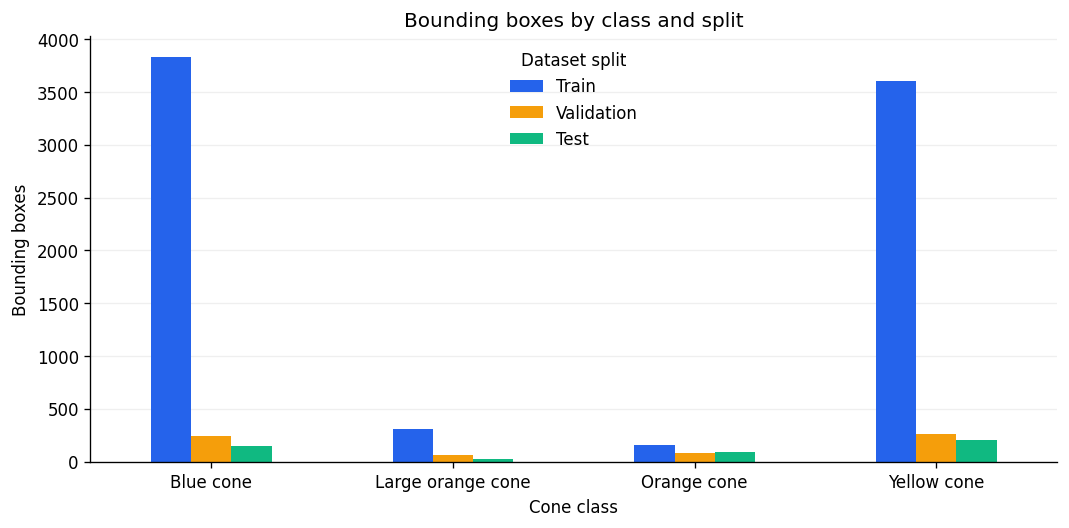

In [ ]:
import matplotlib.pyplot as plt

# Exclude removed images from the statistics and chart.
images_df = images_df.loc[images_df["image"].map(lambda path: Path(path).is_file())].copy()
boxes_df = boxes_df.loc[boxes_df["image"].map(lambda path: Path(path).is_file())].copy()

summary = images_df.groupby("split").agg(
    images=("image", "count"),
    valid_boxes=("valid_boxes", "sum"),
    median_width=("width", "median"),
    median_height=("height", "median"),
).reindex(["train", "val", "test"])

if boxes_df.empty:
    counts = pd.DataFrame(0, index=list(names.values()), columns=list(splits))
else:
    counts = pd.crosstab(boxes_df["class"], boxes_df["split"]).reindex(
        index=list(names.values()), columns=list(splits), fill_value=0
    )

print("Images and valid annotations:")
display(summary)
print("Bounding boxes per class:")
display(counts)
print("Items flagged for review:", len(issues_df))
if not issues_df.empty:
    display(issues_df)
else:
    print("No dataset issues found.")

plot_counts = counts.loc[counts.sum(axis=1) > 0]
if plot_counts.empty:
    plot_counts = counts
plot_counts = plot_counts.rename(
    index=lambda name: str(name).replace("_", " ").capitalize(),
    columns={"train": "Train", "val": "Validation", "test": "Test"},
)
ax = plot_counts.plot.bar(figsize=(9, 4.5), rot=0, color=["#2563EB", "#F59E0B", "#10B981"])
ax.set(title="Bounding boxes by class and split", xlabel="Cone class", ylabel="Bounding boxes")
ax.legend(title="Dataset split", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)
distribution_figure = ax.figure
distribution_figure.tight_layout()
plt.show()

### 4.1. Save the essential report outputs

Save the split and class-count tables as CSV files and the distribution chart as a high-resolution PNG.

In [ ]:
SAVE_REPORT_OUTPUTS = True  # Set False to display results without saving them.
report_dir = root.parent / "data_processing_report"

if SAVE_REPORT_OUTPUTS:
    report_dir.mkdir(exist_ok=True)
    summary.to_csv(report_dir / "split_summary.csv", index_label="split")
    counts.assign(total=counts.sum(axis=1)).to_csv(
        report_dir / "class_counts.csv", index_label="class"
    )
    distribution_figure.savefig(
        report_dir / "class_distribution.png", dpi=300, bbox_inches="tight", facecolor="white"
    )
    print(f"Saved two summary tables and the class-distribution chart to: {report_dir}")
else:
    print("Report output saving is disabled.")

Saved two summary tables and the class-distribution chart to: C:\Users\yumai\lightweight-cnn\data_processing\data_processing_report


## 5. Image sizes and letterboxing

Run cells 5.1-5.9 in order.

### 5.1. Inspect image dimensions

Collect the dimensions and aspect ratios of the remaining readable images.

In [40]:
# Use the remaining, readable images from the audit.
size_df = images_df.loc[
    images_df["image"].map(lambda path: Path(path).is_file()),
    ["split", "image", "width", "height"],
].copy()
if size_df.empty:
    raise ValueError("No images available; run sections 2-4 first.")

size_df["long_side"] = size_df[["width", "height"]].max(axis=1)
size_df["short_side"] = size_df[["width", "height"]].min(axis=1)
size_df["aspect_ratio"] = size_df["width"] / size_df["height"]

Display minimum, maximum, median, mean, and percentile values for the image dimensions.

In [41]:
size_stats = size_df[["width", "height", "long_side", "short_side", "aspect_ratio"]].describe(
    percentiles=[0.1, 0.5, 0.9]
).T.rename(columns={"10%": "p10", "50%": "median", "90%": "p90"})
print("Image dimensions in pixels; aspect_ratio is width / height:")
display(size_stats.round(2))

Image dimensions in pixels; aspect_ratio is width / height:


,count,mean,std,min,p10,median,p90,max
width,706.0,933.01,47.91,776.0,874.0,940.0,960.00,1024.00
height,706.0,529.66,104.28,320.0,346.0,570.0,600.00,830.00
long_side,706.0,933.01,47.91,776.0,874.0,940.0,960.00,1024.00
short_side,706.0,529.66,104.28,320.0,346.0,570.0,600.00,830.00
aspect_ratio,706.0,1.85,0.49,1.2,1.6,1.6,2.67,3.12


### 5.3. Choose the target size

Suggest an editable target from the training-image sizes, rounded up to the model stride.

In [44]:
import math

# Choose the target using training images only.
train_sizes = size_df.loc[size_df["split"] == "train"]
if train_sizes.empty:
    raise ValueError("Training images are required to suggest a target size.")

STRIDE = 32  # Change this if your model requires a different input-size multiple.
suggested_side = math.ceil(train_sizes["long_side"].quantile(0.9) / STRIDE) * STRIDE
TARGET_SIZE = (suggested_side, suggested_side)  # (height, width); edit to override.

print(f"Target (height, width): {TARGET_SIZE}")

Target (height, width): (960, 960)


### 5.4. Define the letterbox transformation

Define how to resize and pad an image while adjusting its normalized bounding boxes.

In [46]:
def letterbox_image(image, boxes, target_size):
    """Resize and center-pad an image, updating normalized YOLO boxes."""
    target_height, target_width = target_size
    width, height = image.size
    scale = min(target_width / width, target_height / height)
    resized_width = max(1, min(target_width, round(width * scale)))
    resized_height = max(1, min(target_height, round(height * scale)))
    left = (target_width - resized_width) // 2
    top = (target_height - resized_height) // 2

    resized = image.resize((resized_width, resized_height), Image.Resampling.BILINEAR)
    padded = Image.new("RGB", (target_width, target_height), (114, 114, 114))
    padded.paste(resized, (left, top))

    adjusted_boxes = [
        (class_id,
         (x * resized_width + left) / target_width,
         (y * resized_height + top) / target_height,
         w * resized_width / target_width,
         h * resized_height / target_height)
        for class_id, x, y, w, h in boxes
    ]
    return padded, adjusted_boxes

### 5.5. Check the settings

Validate the target dimensions and audit results, and show the separate output folder.

In [47]:
if any(not isinstance(size, int) or size <= 0 or size % STRIDE for size in TARGET_SIZE):
    raise ValueError(f"TARGET_SIZE must contain two positive multiples of {STRIDE}.")
if len(TARGET_SIZE) != 2:
    raise ValueError("TARGET_SIZE must be (height, width).")
if image_issues or box_issues:
    raise ValueError("Resolve unreadable images and invalid boxes in section 3 before letterboxing.")

target_height, target_width = TARGET_SIZE
letterbox_root = root.with_name(f"{root.name}-letterboxed-{target_width}x{target_height}").resolve()
if letterbox_root == root.resolve() or letterbox_root.is_relative_to(root.resolve()):
    raise ValueError("The output folder must be separate from the original dataset.")

print(f"Target (height, width): {TARGET_SIZE}")
print(f"Output folder: {letterbox_root}")

Target (height, width): (960, 960)
Output folder: C:\Users\yumai\lightweight-cnn\data_processing\cone-detection-10-letterboxed-960x960


### 5.7. Prepare the output folders

Create image and label folders for each available dataset split.

In [48]:
letterbox_root.mkdir(exist_ok=False)  # Choose a different folder name to make another copy.

letterbox_info = {"path": str(letterbox_root), "nc": len(names), "names": names}
for split, folder in splits.items():
    if (folder / "images").is_dir():
        (letterbox_root / folder.name / "images").mkdir(parents=True)
        (letterbox_root / folder.name / "labels").mkdir(parents=True)
        letterbox_info[split] = f"{folder.name}/images"

print("Output image and label folders are ready.")

Output image and label folders are ready.


### 5.8. Letterbox images and labels

Apply the transformation and save each resized image with its updated label file.

In [49]:
processed_images = processed_boxes = 0
for row in size_df.itertuples(index=False):
    image_path = Path(row.image)
    boxes = boxes_by_image.get(str(image_path), [])
    with Image.open(image_path) as image:
        padded, adjusted_boxes = letterbox_image(image.convert("RGB"), boxes, TARGET_SIZE)

    output_folder = letterbox_root / splits[row.split].name
    output_image = output_folder / "images" / image_path.name
    save_options = {"quality": 95} if output_image.suffix.lower() in {".jpg", ".jpeg"} else {}
    padded.save(output_image, **save_options)
    output_label = output_folder / "labels" / (image_path.stem + ".txt")
    label_text = "".join(
        f"{class_id} " + " ".join(f"{value:.10g}" for value in (x, y, w, h)) + "\n"
        for class_id, x, y, w, h in adjusted_boxes
    )
    output_label.write_text(label_text, encoding="utf-8")
    processed_images += 1
    processed_boxes += len(adjusted_boxes)
    if processed_images % 100 == 0:
        print(f"Processed {processed_images}/{len(size_df)} images...", flush=True)

print(f"Letterboxed {processed_images} images and updated {processed_boxes} bounding boxes.")

Processed 100/706 images...
Processed 200/706 images...
Processed 300/706 images...
Processed 400/706 images...
Processed 500/706 images...
Processed 600/706 images...
Processed 700/706 images...
Letterboxed 706 images and updated 9034 bounding boxes.


### 5.9. Save the dataset configuration

Save the new data.yaml and display the dataset path for training.

In [50]:
letterbox_config = letterbox_root / "data.yaml"
letterbox_config.write_text(yaml.safe_dump(letterbox_info, sort_keys=False), encoding="utf-8")
print(f"Target (height, width): {TARGET_SIZE}")
print(f"New dataset configuration: {letterbox_config}")
print("Original images and labels were preserved.")

Target (height, width): (960, 960)
New dataset configuration: C:\Users\yumai\lightweight-cnn\data_processing\cone-detection-10-letterboxed-960x960\data.yaml
Original images and labels were preserved.


## 6. Visualize a cleaned training sample

Display a letterboxed training image with its transformed bounding boxes and class names, and save the figure when report saving is enabled.

Saved sample figure to: C:\Users\yumai\lightweight-cnn\data_processing\data_processing_report\cleaned_training_sample.png
Training image: utfr_41231_jpg.rf.2fe166ca99011b7a7f8fcb65bd52d7d0.jpg


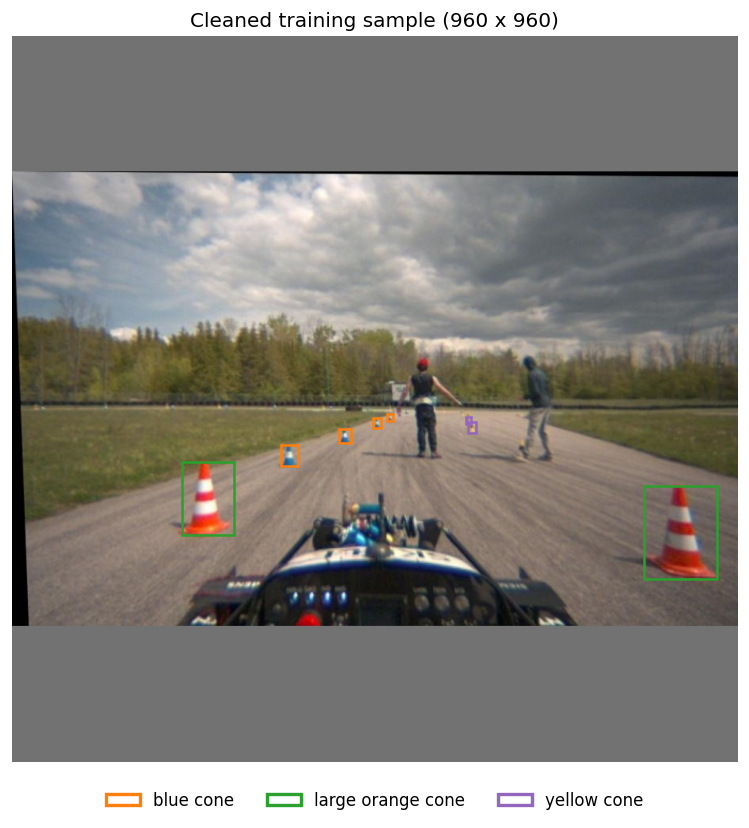

In [ ]:
from matplotlib.patches import Rectangle, Patch

SAMPLE_IMAGE_NAME = None  # Set a filename to show a specific cleaned training image.
candidates = [
    (Path(path), boxes) for path, boxes in boxes_by_image.items()
    if Path(path).parent == splits["train"] / "images" and boxes
]
if not candidates:
    raise ValueError("No annotated training image is available; run the audit first.")


def sample_score(item):
    image_path, boxes = item
    with Image.open(image_path) as image:
        width, height = image.size
    return (2 <= len(boxes) <= 10, len({box[0] for box in boxes}),
            min(width, height) / max(width, height), max(box[3] * box[4] for box in boxes))


original_sample, _ = max(candidates, key=sample_score)
sample_path = letterbox_root / splits["train"].name / "images" / (SAMPLE_IMAGE_NAME or original_sample.name)
sample_label = sample_path.parent.parent / "labels" / (sample_path.stem + ".txt")

fig, ax = plt.subplots(figsize=(9, 7))
with Image.open(sample_path) as image:
    width, height = image.size
    ax.imshow(image)

legend_handles = {}
for line in sample_label.read_text().splitlines():
    if not line.strip():
        continue
    class_id, x, y, w, h = map(float, line.split())
    left, top = (x - w / 2) * width, (y - h / 2) * height
    color = plt.get_cmap("tab10")(int(class_id) % 10)
    ax.add_patch(Rectangle((left, top), w * width, h * height, fill=False, edgecolor=color, linewidth=1.5))
    legend_handles[int(class_id)] = Patch(
        facecolor="none", edgecolor=color, linewidth=2,
        label=names[int(class_id)].replace("_", " "),
    )

ax.set_title(f"Cleaned training sample ({width} x {height})")
ax.axis("off")
ax.legend(handles=[legend_handles[key] for key in sorted(legend_handles)],
          loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3, frameon=False)
fig.tight_layout()
if SAVE_REPORT_OUTPUTS:
    report_dir.mkdir(exist_ok=True)
    fig.savefig(report_dir / "cleaned_training_sample.png", dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Saved sample figure to: {report_dir / 'cleaned_training_sample.png'}")
print("Training image:", sample_path.name)
plt.show()